# LS-RQAOA на CPU

**Версия 0.1.0a5.** Ноутбук проверяет базовый локальный поиск RQAOA:
два построителя, индуцированные подграфы, среднее корреляций по наблюдениям
каждой пары, покрытие, глобальную редукцию, последовательный и параллельный
запуск, энергетический прогресс и локальные углы.

Локальная задача — подграф текущего графа без граничных рёбер и без полей.
Это эвристика, а не точное разложение полного гамильтониана.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import tempfile

from QA_max_cut_lib import GraphFactory, LSRQAOACPU, SolverFactory, tools
from QA_max_cut_lib._version import __version__

PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
print(__version__)
print("package:", Path(__import__("QA_max_cut_lib").__file__).resolve())
assert __version__ == "0.1.0a5"
print(SolverFactory.available())

0.1.0a5
package: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\.venv-wheelcheck\Lib\site-packages\QA_max_cut_lib\__init__.py
('exact_cpu', 'qaoa_cpu', 'rqaoa_cpu', 'ls_rqaoa_cpu')


## Граф больше предела statevector

Граф из 30 вершин и 95 рёбер. Полный вектор состояния на нём не строится;
локальные задачи ограничены размером 10, и аналитический источник p=1
работает без `2**N`.

In [2]:
graph = GraphFactory.from_recipe(
    tools.load_json(PROJECT / "configs/graphs/erdos_signed_30.json")
)
print("N:", len(graph), "E:", len(graph.edges))
print("labels:", graph.nodes[:8], "...")

N: 30 E: 128
labels: (0, 1, 2, 3, 4, 5, 6, 7) ...


## Построители и индуцированные задачи

In [3]:
from QA_max_cut_lib.generators import (
    GreedyAbsWeightPartitionBuilder,
    RandomPartitionBuilder,
)

random_builder = RandomPartitionBuilder({
    "type": "random_partition",
    "parameters": {"max_size": 8, "rounds": 2, "full_graph_when_fits": False},
}, seed=20261102)
greedy_builder = GreedyAbsWeightPartitionBuilder({
    "type": "greedy_abs_weight_partition",
    "parameters": {"max_size": 10, "rounds": 2, "full_graph_when_fits": False},
}, seed=20261102)
for name, builder in (("random", random_builder), ("greedy", greedy_builder)):
    tasks = builder.build(graph, version=0)
    sizes = [len(task["nodes"]) for task in tasks]
    print(name, "tasks:", len(tasks), "sizes:", sizes[:8], "max:", max(sizes))
    assert all(size <= builder.max_size for size in sizes)

random tasks: 8 sizes: [8, 8, 8, 6, 8, 8, 8, 6] max: 8
greedy tasks: 6 sizes: [10, 10, 10, 10, 10, 10] max: 10


## Последовательный аналитический LS-RQAOA

`limits.shots_total=0`, потому что локальные корреляции считаются точно.
Каждая задача имеет свои углы; `parameter_trajectory` хранит строки задач, а
не синтетическую глобальную траекторию.

In [4]:
sequential_config = tools.load_json(
    PROJECT / "configs/solvers/ls_rqaoa_analytic.json"
)
sequential_config.pop("save", None)
sequential_config["num_treads"] = 1
sequential_config["parameters"]["finish_at"] = 6
sequential = LSRQAOACPU(sequential_config)
sequential_solution = sequential.solve(graph, report=0, logs=0)
print("status:", sequential.status)
print("cut:", sequential.cut_value, "energy:", sequential.solution_energy)
print("reductions:", sequential.reductions_completed,
      "source:", sequential.solution_source)
print("tasks:", sequential.resources["local_tasks_total"],
      "shots:", sequential.resources["shots_used"])
assert set(sequential_solution) == set(graph.nodes)
assert sequential.solution_energy == -graph.cut_value(sequential_solution)
assert sequential.resources["shots_used"] == 0
assert sequential.coverage_history

status: completed
cut: 41.74654631200346 energy: -41.74654631200346
reductions: 24 source: exact_finisher
tasks: 98 shots: 0


## Покрытие пар

In [5]:
for row in sequential.coverage_history[:3]:
    print(row["task_version"], "allowed", row["allowed_pairs"],
          "observed", row["observed_pairs"], "missing", row["missing_pairs"],
          "fraction", row["fraction"], "repair", row["repair_added"])

0 allowed 128 observed 86 missing 42 fraction 0.671875 repair False
1 allowed 126 observed 71 missing 55 fraction 0.5634920634920635 repair False
2 allowed 123 observed 69 missing 54 fraction 0.5609756097560976 repair False


## Реальный параллельный запуск через CLI

Прямой `spawn` из Jupyter на Windows не является надёжным, поэтому ноутбук
запускает импортируемый CLI как подпроцесс. Это не подмена параллельного
режима последовательным: CLI выбирает `num_treads=2` и создаёт пул процессов.

In [6]:
with tempfile.TemporaryDirectory(prefix="ls_rqaoa_") as tmp:
    parallel_config = tools.load_json(
        PROJECT / "configs/solvers/ls_rqaoa_analytic.json"
    )
    parallel_config["num_treads"] = 2
    parallel_config["parameters"]["finish_at"] = 6
    parallel_config["save"] = {
        "path": str(Path(tmp) / "results"),
        "atts": ["solution", "cut_value", "solution_energy", "reduction_history", "parameter_trajectory", "local_task_history", "coverage_history"],
        "filename": "parallel_cli",
        "save_original_data": [],
        "makedir": True,
        "savedir": True,
    }
    parallel_config_path = Path(tmp) / "parallel.json"
    parallel_config_path.write_text(json.dumps(parallel_config), encoding="utf-8")
    completed = subprocess.run(
        [sys.executable, "-m", "QA_max_cut_lib.solvers.ls_rqaoa_cpu",
         "--graph", str(PROJECT / "configs/graphs/erdos_signed_30.json"),
         "--config", str(parallel_config_path), "--report", "0", "--logs", "0"],
        cwd=PROJECT, text=True, capture_output=True, check=False,
    )
    print("exit:", completed.returncode)
    assert completed.returncode == 0, completed.stderr
    parallel_record = tools.load_result(
        Path(tmp) / "results" / "parallel_cli" / "parallel_cli.json"
    )
print("parallel requested/applied:",
      parallel_record.get("resources")["num_treads_requested"],
      parallel_record.get("resources")["num_treads_applied"])
print("parallel cut:", parallel_record.get("cut_value"))
assert parallel_record.get("solution") == sequential_solution

exit: 0
parallel requested/applied: 2 2
parallel cut: 41.74654631200346


## Энергетический прогресс и покрытие

Figure 4
Figure 2
Figure 2


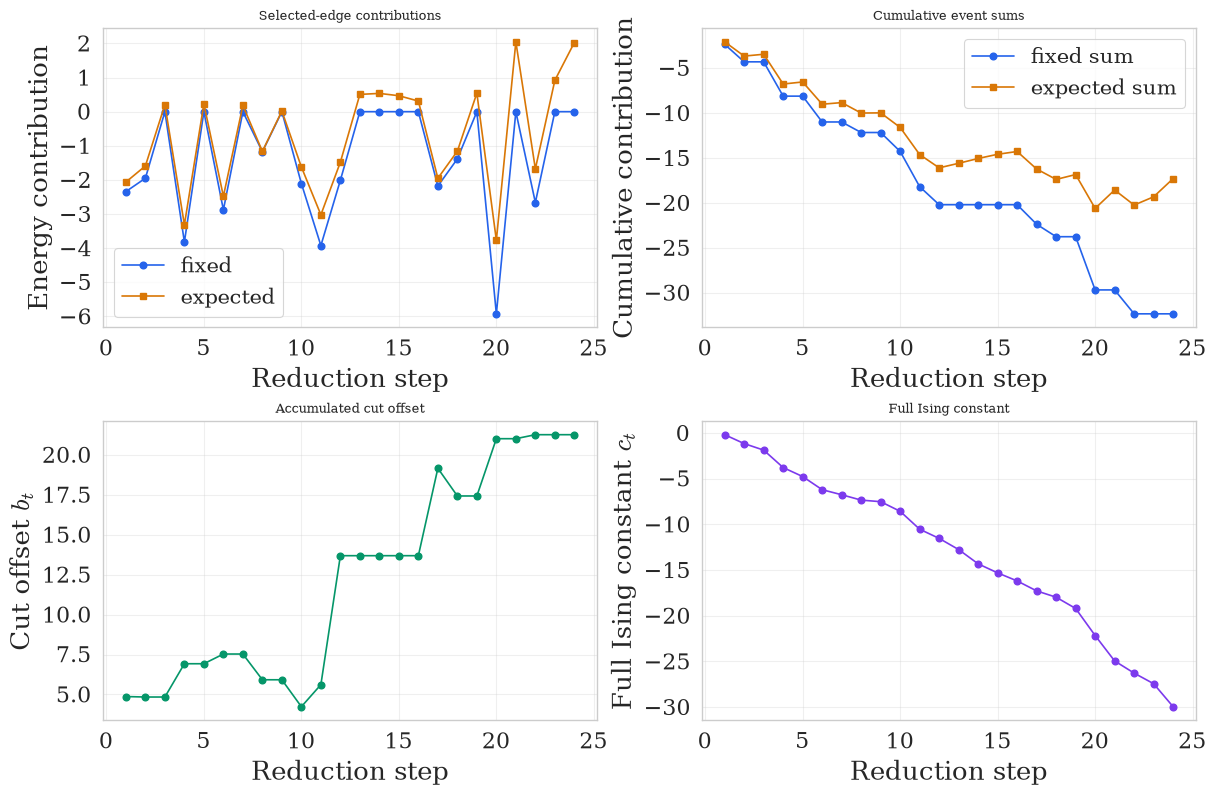

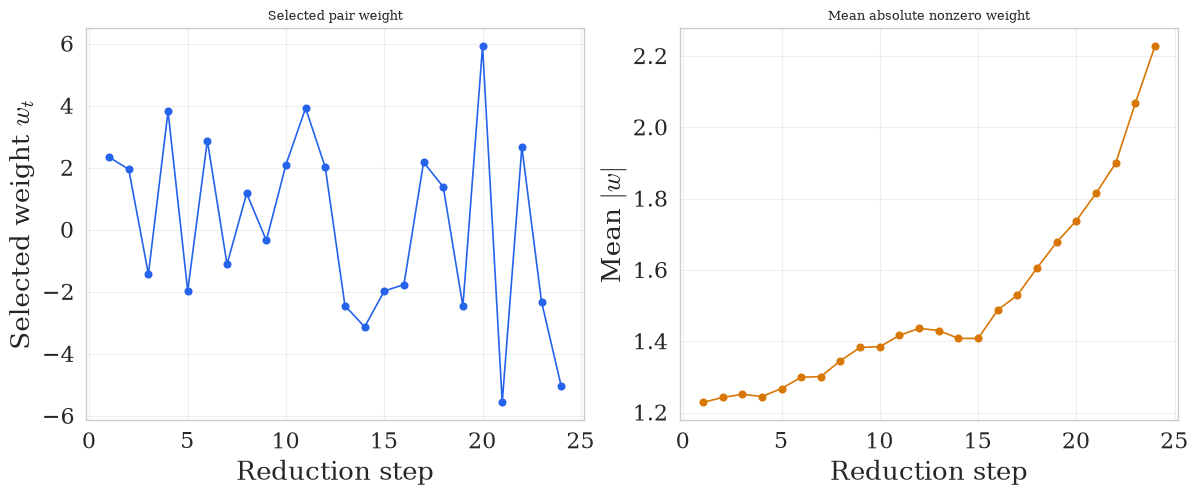

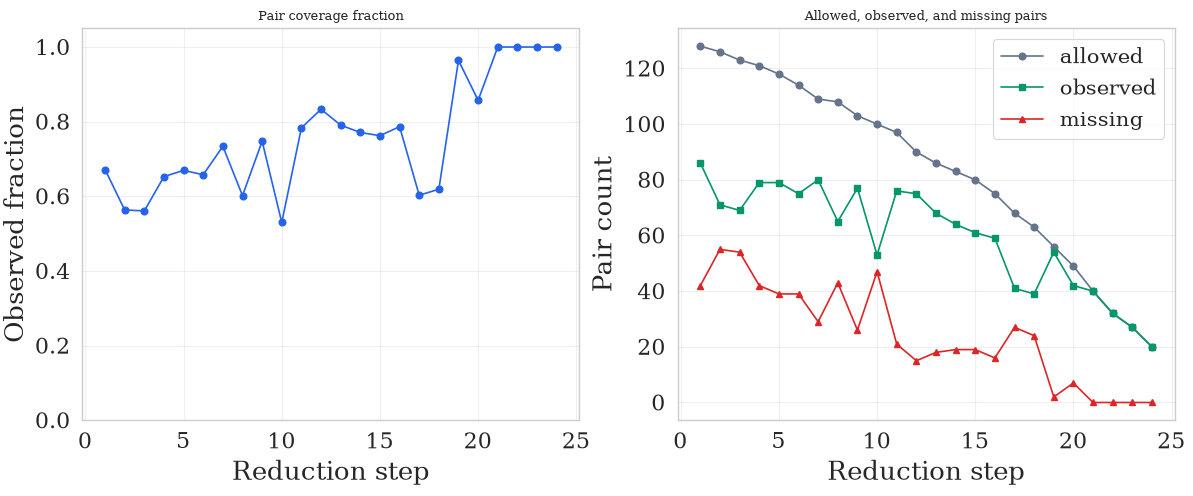

In [7]:
energy_figure = tools.plot_reduction_energy(sequential)
weights_figure = tools.plot_reduction_weights(sequential)
coverage_figure = tools.plot_ls_coverage(sequential)
print(type(energy_figure).__name__, len(energy_figure.axes))
print(type(weights_figure).__name__, len(weights_figure.axes))
print(type(coverage_figure).__name__, len(coverage_figure.axes))

## Локальные углы: все пары параметров

In [8]:
trajectory_figure = tools.plot_parameter_trajectories(sequential)
trajectory_3d = tools.plot_parameter_trajectories_3d(sequential)
output_dir = PROJECT / "notebooks/_outputs"
output_dir.mkdir(parents=True, exist_ok=True)
trajectory_figure.savefig(output_dir / "ls_trajectory_2d.png", dpi=160)
trajectory_3d.write_html(
    output_dir / "ls_trajectory_3d.html", include_plotlyjs=True, full_html=True
)
print("rows:", len(sequential.parameter_trajectory))
print("task ids:", sorted({row["task_id"] for row in sequential.parameter_trajectory})[:6])
assert (output_dir / "ls_trajectory_3d.html").stat().st_size > 1000

C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\.venv-wheelcheck\Lib\site-packages\QA_max_cut_lib\tools\plotting.py:131: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


rows: 98
task ids: ['r0:p0:b0', 'r0:p0:b1', 'r0:p0:b2', 'r0:p1:b0', 'r0:p1:b1', 'r0:p1:b2']


## Statevector p=2

Второй источник использует уже существующий полный симулятор на локальных
подграфах; предел проверяется по размеру локальной задачи, а не родителя.

In [9]:
small_graph = GraphFactory.from_recipe({
    "type": "complete", "seed": 5,
    "parameters": {"n_vertices": 8},
    "weights": {"type": "signed_discrete", "parameters": {"values": [-1.0, 1.0]}, "seed": 6},
})
state_config = tools.load_json(
    PROJECT / "configs/solvers/ls_rqaoa_statevector_p2.json"
)
state_config.pop("save", None)
state_config["num_treads"] = 1
state_config["parameters"]["finish_at"] = 3
state_solver = LSRQAOACPU(state_config)
state_solution = state_solver.solve(small_graph, report=0, logs=0)
print("statevector:", state_solver.status, state_solver.cut_value,
      "reductions", state_solver.reductions_completed,
      "tasks", state_solver.resources["local_tasks_total"])
assert state_solver.reductions_completed > 0
assert set(state_solution) == set(small_graph.nodes)

statevector: completed 9.0 reductions 5 tasks 10


## Остановка по общему шотовому бюджету

Координатор резервирует корреляционные выборки и квоты обучения до запуска
worker-процессов. При нехватке возвращается полное допустимое решение,
`status="stopped"` и честная причина.

In [10]:
shot_config = tools.load_json(PROJECT / "configs/solvers/ls_rqaoa_shots.json")
shot_config.pop("save", None)
shot_config["num_treads"] = 2
shot_config["limits"]["shots_total"] = 1000
shot_solver = LSRQAOACPU(shot_config)
shot_solution = shot_solver.solve(graph, report=0, logs=0)
print("shots:", shot_solver.status, shot_solver.termination_reason,
      shot_solver.resources["shots_used"])
assert set(shot_solution) == set(graph.nodes)
assert shot_solver.resources["shots_used"] <= 1000
assert shot_solver.status in {"completed", "stopped"}

shots: stopped shot_budget 0


## Итог

In [11]:
print("version:", __version__)
print("sequential cut:", sequential.cut_value)
print("parallel cut:", parallel_record.get("cut_value"))
print("parallel tasks:", parallel_record.get("resources")["local_tasks_total"])
print("3D HTML:", output_dir / "ls_trajectory_3d.html")

version: 0.1.0a5
sequential cut: 41.74654631200346
parallel cut: 41.74654631200346
parallel tasks: 98
3D HTML: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\notebooks\_outputs\ls_trajectory_3d.html
